# 第6回 予測精度の検証 ― モデルは未来を当てられるか

**使い方**：上のセルから順に `Shift + Enter` で実行していきます。コードを書き換える必要はありません。
「🧪 実験」のセルだけは、値を変えて何度か実行してみてください。

**この回のゴール**

1. モデルが学習に使っていない26週（テスト用データ）の売上を予測する
2. 予測の良し悪しを、複数の指標と「単純な予測」との比較で評価する
3. その結果が、第5回の ROAS などの信頼性について何を意味するかを考える

**所要時間**：45分ほど。重い計算はありません。

**前提**：第4回で保存した学習結果（`mmm_cs1.nc`）を使います。まだ無いときは、この回の中で学習します（3〜13分）。

> **この教材について**
>
> - PyMC-Marketing の公式ケーススタディ「[MMM End-to-End Case Study](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_case_study.html)」を、日本語で順に学べるように組み立て直した教材です（作成：Birdwing Technologies合同会社）。
> - コードは本家（Apache License 2.0）をもとに改変しています。解説・図・小課題は独自に加えたものです。
> - データは本家と同じ、公開されている学習用のデータです。
> - 解説ページと全体の目次：<https://bwtech.co.jp/learn/mmm/06-out-of-sample>

## 0. 準備

最初のセルは、どの回にも共通の準備です。**Google Colab でも、自分のPCでも、そのまま実行できます。**

- データがなければダウンロードします（約80KB）
- グラフに日本語を表示できるようにします
- Google Colab のときだけ、必要なライブラリを入れます（数分かかります）
- 学習結果の置き場所を決めます（Colab のときは Google ドライブ。初回に許可の画面が出ます）

In [1]:
# ===== 共通の準備（Google Colab でも、自分のPCでも、このまま実行できます） =====
import subprocess, sys, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# --- g++（計算を速くする部品）がない環境では、その旨を PyTensor に伝える（WARNING が短くなる） ---
import os, shutil
if shutil.which("g++") is None:
    os.environ["PYTENSOR_FLAGS"] = "cxx="

# --- Colab のときだけ、ライブラリを入れる（数分かかります） ---
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymc-marketing==0.19.2", "nutpie==0.16.8"], check=True)

# --- ファイルの置き場所 ---
BASE_DIR = Path("/content/mmm-pymc") if IN_COLAB else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "case_study_data.csv"

# --- 学習結果の置き場所 ---
# Colab は接続が切れるとファイルが消えるので、学習結果は Google ドライブに置く（初回に許可の画面が出ます）。
# ドライブを使いたくないときは USE_DRIVE = False にする（その場合は、回ごとに学習し直します）。
USE_DRIVE = True
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    MODEL_DIR = Path("/content/drive/MyDrive/mmm-pymc/models")
else:
    MODEL_DIR = BASE_DIR / "models"
MODEL_PATH = MODEL_DIR / "mmm_cs1.nc"

# --- データの取得（なければダウンロードする） ---
DATA_URL = "https://raw.githubusercontent.com/pymc-labs/pymc-marketing/0.19.2/data/case_study_data.csv"
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

# --- グラフの日本語フォント ---
import matplotlib.pyplot as plt
from matplotlib import font_manager

def setup_japanese_font():
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["Meiryo", "Yu Gothic", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "IPAGothic"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            return name
    # 日本語フォントが見つからないとき（Colab など）は、フォント入りのパッケージを入れる
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib-fontja"], check=True)
    import matplotlib_fontja  # 読み込むだけで日本語フォント（IPAexGothic）が設定される
    return "IPAexGothic"

font_name = setup_japanese_font()
plt.rcParams["axes.unicode_minus"] = False    # マイナス記号の文字化けを防ぐ

print("実行環境:", "Google Colab" if IN_COLAB else "自分のPC")
print("データ:", DATA_PATH.relative_to(BASE_DIR).as_posix(), "（取得済み）")
print("日本語フォント:", font_name)

実行環境: 自分のPC
データ: data/case_study_data.csv （取得済み）
日本語フォント: Meiryo


この回で使うライブラリを読み込みます。

In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pymc_marketing.metrics import crps
from pymc_marketing.mmm.multidimensional import MMM

SEED = 42
FAST = {"mode": "NUMBA"}


WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


### 学習結果を読み込む

第4回で保存した学習結果（`mmm_cs1.nc`）を読み込みます。

- 見つかったとき → 読み込むだけ（数秒）
- 見つからないとき → 第4回と同じ設定で、この場で学習して保存します（**3〜13分**）

In [3]:
def load_or_fit_model():
    """学習結果を読み込む。なければ、第4回と同じ設定で学習して保存する。"""
    if MODEL_PATH.exists():
        print("保存済みの学習結果を読み込みました:", MODEL_PATH.name)
        return MMM.load(str(MODEL_PATH))

    print("学習結果が見つからないので、第4回と同じ設定で学習します（3〜13分）。")
    from pymc_extras.prior import Prior
    from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation

    raw = pd.read_csv(DATA_PATH, parse_dates=["wk_strt_dt"])
    names = {
        "mdsp_dm": "DM", "mdsp_inst": "折込", "mdsp_nsp": "新聞", "mdsp_audtr": "ラジオ",
        "mdsp_vidtr": "TV", "mdsp_so": "ソーシャル", "mdsp_on": "ディスプレイ",
    }
    channels = list(names.values())
    controls = [c for c in raw.columns if c.startswith("hldy_")]
    data = raw[["wk_strt_dt", "sales", *names.keys(), *controls]].rename(columns=names)
    train = data[data["wk_strt_dt"] <= pd.to_datetime("2018-02-01")]
    X_tr, y_tr = train.drop(columns="sales"), train["sales"]
    share = X_tr[channels].sum() / X_tr[channels].sum().sum()

    model = MMM(
        model_config={
            "intercept": Prior("Normal", mu=0.2, sigma=0.05),
            "saturation_beta": Prior("HalfNormal", sigma=share[channels].to_numpy(), dims="channel"),
            "gamma_control": Prior("Normal", mu=0, sigma=1, dims="control"),
            "gamma_fourier": Prior("Laplace", mu=0, b=1, dims="fourier_mode"),
            "likelihood": Prior("TruncatedNormal", lower=0, sigma=Prior("HalfNormal", sigma=1)),
        },
        date_column="wk_strt_dt", target_column="sales",
        channel_columns=channels, control_columns=controls,
        adstock=GeometricAdstock(l_max=6), saturation=LogisticSaturation(), yearly_seasonality=5,
    )
    model.build_model(X_tr, y_tr)
    model.add_original_scale_contribution_variable(
        var=["channel_contribution", "control_contribution", "intercept_contribution",
             "yearly_seasonality_contribution", "y"]
    )
    model.fit(X_tr, y_tr, chains=4, tune=1_000, draws=1_000, target_accept=0.9,
              nuts_sampler="nutpie", random_seed=42)
    model.sample_posterior_predictive(X_tr, extend_idata=True, combined=True, random_seed=42,
                                      compile_kwargs={"mode": "NUMBA"})
    for group in ["warmup_posterior", "warmup_sample_stats"]:
        if group in model.idata.groups():
            del model.idata[group]
    MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
    model.save(str(MODEL_PATH))
    return model

mmm = load_or_fit_model()


保存済みの学習結果を読み込みました: mmm_cs1.nc


データを、第3〜4回と同じ方法で学習用とテスト用に分けます。

In [4]:
raw_df = pd.read_csv(DATA_PATH, parse_dates=["wk_strt_dt"])

channel_names = {
    "mdsp_dm": "DM", "mdsp_inst": "折込", "mdsp_nsp": "新聞", "mdsp_audtr": "ラジオ",
    "mdsp_vidtr": "TV", "mdsp_so": "ソーシャル", "mdsp_on": "ディスプレイ",
}
channel_columns = list(channel_names.values())
control_columns = [c for c in raw_df.columns if c.startswith("hldy_")]
date_column, target_column = "wk_strt_dt", "sales"

data_df = raw_df[[date_column, target_column, *channel_names.keys(), *control_columns]].rename(columns=channel_names)

split_date = pd.to_datetime("2018-02-01")
train_df = data_df[data_df[date_column] <= split_date]
test_df = data_df[data_df[date_column] > split_date]
X_train, y_train = train_df.drop(columns=target_column), train_df[target_column].to_numpy()
X_test, y_test = test_df.drop(columns=target_column), test_df[target_column].to_numpy()
train_dates, test_dates = train_df[date_column], test_df[date_column]

print(f"学習用: {len(train_df)} 週（{train_dates.min().date()} 〜 {train_dates.max().date()}）")
print(f"テスト用: {len(test_df)} 週（{test_dates.min().date()} 〜 {test_dates.max().date()}）")

学習用: 183 週（2014-08-03 〜 2018-01-28）
テスト用: 26 週（2018-02-04 〜 2018-07-29）


## 1. なぜテスト用データで確かめるのか

第4回の事後予測チェックでは、学習に使ったデータへの当てはまりを見ました。しかし、それだけでは足りません。

- パラメータが55個もあるモデルは、学習用データの**偶然の上下まで覚えてしまう**ことがあります（過学習）
- 過学習したモデルは、学習用データにはよく当てはまるのに、新しいデータでは外れます
- だから、**モデルが一度も見ていないデータ**で試します。テストの答えを先に見せずに、実力を測るのと同じです

本家のノートブックも、こう書いています。「モデルの提案に従うなら、過去を説明できるだけでなく、予測もできるという証拠が必要だ。これは事業側の納得を得るための鍵になる」

### テスト期間はどんな期間か

評価の前に、テスト期間が学習期間とどう違うかを確認します。

In [5]:
period = pd.DataFrame({
    "学習用（週平均、万）": (train_df[channel_columns].mean() / 1e4).round(1),
    "テスト用（週平均、万）": (test_df[channel_columns].mean() / 1e4).round(1),
})
period["テスト ÷ 学習"] = (period["テスト用（週平均、万）"] / period["学習用（週平均、万）"]).round(2)

print("売上の週平均：学習用", round(y_train.mean() / 1e8, 2), "億 / テスト用", round(y_test.mean() / 1e8, 2), "億")
print("広告費合計の週平均：学習用", round(train_df[channel_columns].sum(axis=1).mean() / 1e4), "万 / テスト用",
      round(test_df[channel_columns].sum(axis=1).mean() / 1e4), "万")
test_holidays = [c.replace("hldy_", "") for c in control_columns if test_df[c].sum() > 0]
print("テスト期間にある祝日:", test_holidays)
period

売上の週平均：学習用 1.1 億 / テスト用 0.95 億
広告費合計の週平均：学習用 178 万 / テスト用 116 万
テスト期間にある祝日: ['Easter', "Father's Day", 'July 4th', 'Memorial Day', "Mother's Day", 'Presidents Day', 'Prime Day', "Valentine's Day"]


,学習用（週平均、万）,テスト用（週平均、万）,テスト ÷ 学習
DM,79.9,46.6,0.58
折込,8.5,4.1,0.48
新聞,28.9,1.1,0.04
ラジオ,12.2,13.0,1.07
TV,17.8,10.0,0.56
ソーシャル,9.3,16.5,1.77
ディスプレイ,21.1,25.0,1.18


**読み方**：テスト期間は、学習期間とかなり様子が違います。

- **年末を含まない**（2月〜7月）。売上の週平均は0.95億で、学習期間（1.10億）より低い
- **広告費の合計は約3分の2**（週178万 → 116万）
- **チャネルの使い方が変わっている**：新聞はほぼ停止（学習期間の4%）、DM・TV・折込は約半分、ソーシャルは約1.8倍

つまりこのテストは、「いつもと同じ出し方が続いたとき」ではなく、「**広告の出し方が変わったとき**に予測できるか」も試しています。MMMにとっては、より意味のある検証です。

## 2. テスト期間を予測する

学習済みのモデルに、テスト期間の広告費と祝日フラグ（`X_test`）を渡して、売上を予測させます。売上（`y_test`）は渡しません。

- `include_last_observations=True`：学習期間の最後の数週の広告費も一緒に渡します。
  adstock があるので、テスト期間の最初の週には、その前の週の広告の効果が残っているからです
- 予測は、4,000組のパラメータそれぞれについて行われます。誤差（σ）も加えた「実際に観測されそうな売上」が4,000通り得られます
- 読み込んだモデルの予測値は 0〜1 にそろえた単位で出てくるので、最大売上（`target_scale`）をかけて元の単位に戻します

In [6]:
pred = mmm.sample_posterior_predictive(
    X_test,
    include_last_observations=True,
    var_names=["y"],
    extend_idata=False,
    combined=False,
    random_seed=SEED,
    compile_kwargs=FAST,
)
target_scale = float(mmm.idata["constant_data"]["target_scale"].values[0])
y_pred_test = pred["y"] * target_scale          # 4チェーン × 1,000ドロー × 26週
print(dict(y_pred_test.sizes))

Sampling: [y]


Output()

{'chain': 4, 'draw': 1000, 'date': 26}


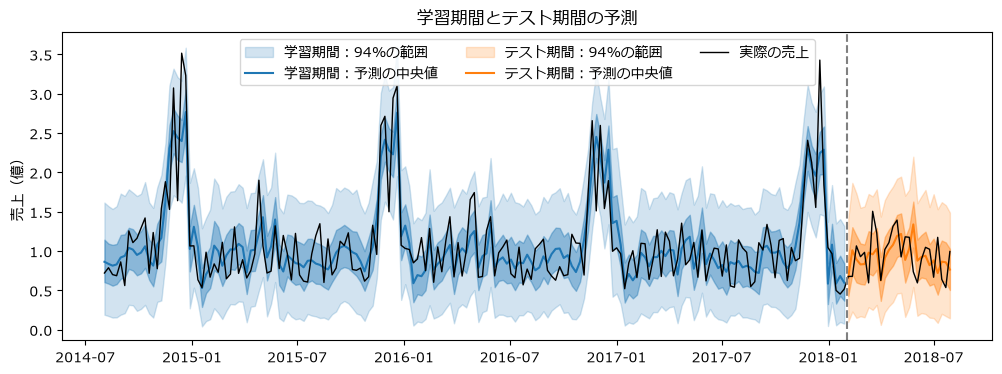

In [7]:
S = ("chain", "draw")

# 学習期間の予測（第4回で計算して保存してあるもの）
y_pred_train = mmm.idata["posterior_predictive"]["y_original_scale"]
train_sample_dims = [d for d in y_pred_train.dims if d != "date"]

def bands(y_pred, sample_dims):
    # 予測サンプルを、週ごとの [3%, 25%, 50%, 75%, 97%] にまとめる
    return y_pred.quantile([0.03, 0.25, 0.5, 0.75, 0.97], dim=sample_dims).to_numpy()

q_train = bands(y_pred_train, train_sample_dims)
q_test = bands(y_pred_test, S)

fig, ax = plt.subplots(figsize=(12, 4))
for q, dates, color, label in [(q_train, train_dates, "C0", "学習期間"), (q_test, test_dates, "C1", "テスト期間")]:
    ax.fill_between(dates, q[0] / 1e8, q[4] / 1e8, alpha=0.2, color=color, label=f"{label}：94%の範囲")
    ax.fill_between(dates, q[1] / 1e8, q[3] / 1e8, alpha=0.4, color=color)
    ax.plot(dates, q[2] / 1e8, color=color, linewidth=1.5, label=f"{label}：予測の中央値")
ax.plot(data_df[date_column], data_df[target_column] / 1e8, color="black", linewidth=1, label="実際の売上")
ax.axvline(split_date, color="gray", linestyle="--")
ax.set_ylabel("売上（億）")
ax.set_title("学習期間とテスト期間の予測")
ax.legend(loc="upper center", ncol=3);

点線より右のオレンジ色が、モデルが売上を見ずに予測した26週です。拡大します。

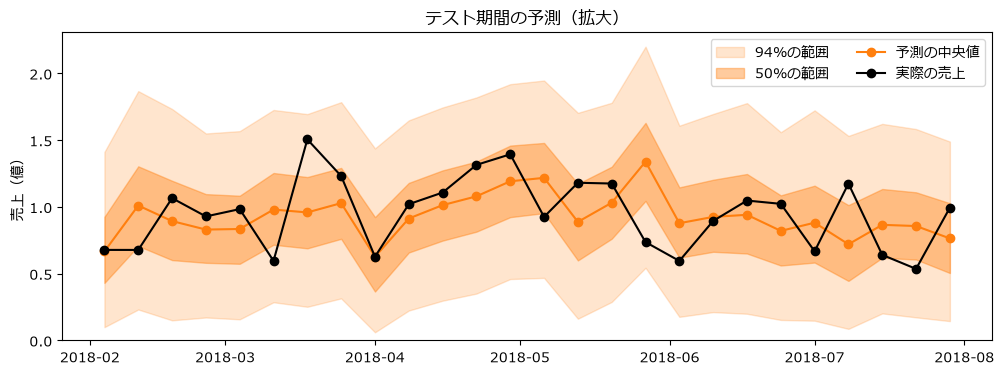

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(test_dates, q_test[0] / 1e8, q_test[4] / 1e8, alpha=0.2, color="C1", label="94%の範囲")
ax.fill_between(test_dates, q_test[1] / 1e8, q_test[3] / 1e8, alpha=0.4, color="C1", label="50%の範囲")
ax.plot(test_dates, q_test[2] / 1e8, color="C1", marker="o", label="予測の中央値")
ax.plot(test_dates, y_test / 1e8, color="black", marker="o", label="実際の売上")
ax.set_ylim(0, None)
ax.set_ylabel("売上（億）")
ax.set_title("テスト期間の予測（拡大）")
ax.legend(loc="upper right", ncol=2);

**読み方**

- 実際の売上（黒）は、26週すべてで94%の範囲（うすいオレンジ）に入っています
- 予測の中央値（オレンジの線）は、4〜5月にゆるやかに高くなる流れをとらえています
- 一方、週ごとの大きな上下（3月中旬の山、5月末の谷など）は追えていません。5月末は、予測が上がったのに実際は下がっています
- 94%の範囲の幅は約1.5億で、売上そのもの（約1億）より広い。「0.2億〜1.7億のどこか」という予測です

本家のノートブックは、この図について「とても良い」と書いています。本当にそう言えるか、数字で確かめます。

## 3. 指標で評価する

図の印象だけでなく、数字で評価します。指標は見ているものが違うので、複数を使います。

| 指標 | 意味 | 良い値 |
|---|---|---|
| 平均誤差率（MAPE） | 予測の中央値と実際のずれが、平均で何%か | 小さいほど良い |
| 決定係数（R²） | 週ごとの上下を、どれだけ説明できたか。「期間の平均をそのまま予測する」場合が0 | 1に近いほど良い |
| 合計の比 | 期間合計の予測 ÷ 実際。全体として多め・少なめに偏っていないか | 1に近いほど良い |
| 94%の範囲に入った割合 | 予測の幅が適切か | 94%に近いほど良い |
| 50%の範囲に入った割合 | 同上 | 50%に近いほど良い |

学習期間とテスト期間を並べます。

In [9]:
def evaluate(y_true, q):
    low94, low50, med, high50, high94 = q
    return {
        "平均誤差率（MAPE）": f"{np.mean(np.abs(y_true - med) / y_true):.1%}",
        "決定係数（R²）": round(1 - ((y_true - med) ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum(), 2),
        "合計の比（予測 ÷ 実際）": round(med.sum() / y_true.sum(), 3),
        "94%の範囲に入った割合": f"{((y_true >= low94) & (y_true <= high94)).mean():.0%}",
        "50%の範囲に入った割合": f"{((y_true >= low50) & (y_true <= high50)).mean():.0%}",
        "94%の範囲の幅（平均、億）": round((high94 - low94).mean() / 1e8, 2),
    }

# 学習期間のうち、年末（11〜12月）を除いた週だけでも評価する
offpeak = ~train_dates.dt.month.isin([11, 12]).to_numpy()

metrics = pd.DataFrame({
    "学習期間（183週）": evaluate(y_train, q_train),
    "学習期間・年末を除く": evaluate(y_train[offpeak], q_train[:, offpeak]),
    "テスト期間（26週）": evaluate(y_test, q_test),
})
metrics

,学習期間（183週）,学習期間・年末を除く,テスト期間（26週）
平均誤差率（MAPE）,25.2%,24.8%,26.2%
決定係数（R²）,0.69,0.16,-0.05
合計の比（予測 ÷ 実際）,0.994,0.992,0.977
94%の範囲に入った割合,97%,100%,100%
50%の範囲に入った割合,57%,64%,65%
94%の範囲の幅（平均、億）,1.47,1.45,1.47


**読み方**

- **平均誤差率**：学習期間25.2%、テスト期間26.2%。ほとんど同じです。**過学習はしていません**。見たことのないデータでも、同じ程度の精度が出ています
- **合計の比**：0.98〜0.99。全体として多め・少なめに偏ってはいません
- **範囲に入った割合**：94%の範囲に100%、50%の範囲に65%。目標（94%と50%）より多く入っているので、予測の幅は少し広すぎます（慎重すぎる予測）

**決定係数 R² に注目してください。**

- 学習期間全体では0.69ですが、**年末を除くと0.16**に下がります。テスト期間は −0.05 です
- R² は「期間の平均をそのまま予測する」よりどれだけ良いかを表します。0以下は、平均を予測するのと変わらないという意味です
- つまり、このモデルが説明できているのは主に**年末の大きな山**で、ふだんの週の上下はほとんど説明できていません

第4回で見た「R² 0.69」は、年末の山があるおかげで高く出ていた数字でした。**指標は、どの期間で測ったかによって大きく変わります。**

## 4. 単純な予測と比べる

誤差率が何%なら良いのかは、それだけでは判断できません。**何も工夫しない単純な予測**と比べて初めて、モデルの価値が分かります。

2つの単純な予測を用意します。どちらも、広告費の情報を一切使いません。

- **学習期間の平均**：毎週、学習期間の平均売上をそのまま予測する
- **前年同週**：52週前の売上を、そのまま予測する

,MMM（予測の中央値）,前年同週,学習期間の平均
平均誤差率（MAPE）,26.2%,24.0%,33.1%
平均絶対誤差（億）,0.228,0.214,0.248
決定係数（R²）,-0.05,-0.49,-0.31
合計の比（予測 ÷ 実際）,0.977,0.969,1.156


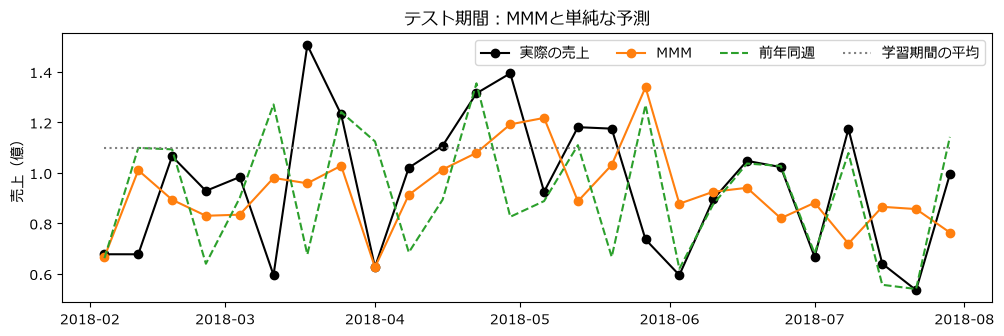

In [10]:
sales_by_date = data_df.set_index(date_column)[target_column]

naive_mean = np.full(len(y_test), y_train.mean())
naive_last_year = np.array([sales_by_date.loc[d - pd.Timedelta(weeks=52)] for d in test_dates])
model_median = q_test[2]

def point_metrics(y_true, y_hat):
    return {
        "平均誤差率（MAPE）": f"{np.mean(np.abs(y_true - y_hat) / y_true):.1%}",
        "平均絶対誤差（億）": round(np.mean(np.abs(y_true - y_hat)) / 1e8, 3),
        "決定係数（R²）": round(1 - ((y_true - y_hat) ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum(), 2),
        "合計の比（予測 ÷ 実際）": round(y_hat.sum() / y_true.sum(), 3),
    }

baseline = pd.DataFrame({
    "MMM（予測の中央値）": point_metrics(y_test, model_median),
    "前年同週": point_metrics(y_test, naive_last_year),
    "学習期間の平均": point_metrics(y_test, naive_mean),
})

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(test_dates, y_test / 1e8, color="black", marker="o", label="実際の売上")
ax.plot(test_dates, model_median / 1e8, color="C1", marker="o", label="MMM")
ax.plot(test_dates, naive_last_year / 1e8, color="C2", linestyle="--", label="前年同週")
ax.plot(test_dates, naive_mean / 1e8, color="gray", linestyle=":", label="学習期間の平均")
ax.set_ylabel("売上（億）")
ax.set_title("テスト期間：MMMと単純な予測")
ax.legend(ncol=4)
baseline

**読み方**

- 平均誤差率は、MMM 26.2%、前年同週 24.0%、学習期間の平均 33.1%
- **MMMは「学習期間の平均」よりは良いが、「前年同週」とほぼ同じ**（わずかに負けています）
- R² は3つともマイナスです。どの方法も、テスト期間の週ごとの上下は当てられていません
- 合計の比は、MMM 0.977、前年同週 0.969。全体の水準はどちらもよく当たっています

しかも MMM は、テスト期間の広告費と祝日を知ったうえで予測しています。前年同週は何も使っていません。
**週ごとの売上を予測する道具としては、このMMMは「去年の同じ週を見る」のと同じ程度**、というのが正直な評価です。

誤差率26%という数字だけを見ても、良いのか悪いのか分かりませんでした。単純な予測と並べて初めて、位置づけが分かります。

## 5. CRPS ― 予測の「幅」も含めて評価する

これまでの指標の多くは、予測の中央値（1つの数字）だけを評価していました。しかしベイズ推定の予測は**分布**です。
分布全体の良し悪しを1つの数字にするのが **CRPS**（Continuous Ranked Probability Score）で、本家のノートブックもこれを使っています。

- 予測の分布が実際の値の近くに集中しているほど、小さく（良く）なります
- 幅が広すぎても、狭すぎて外しても、悪くなります
- 予測が1つの数字だけのとき、CRPS は平均絶対誤差と同じになります。だから、単純な予測の平均絶対誤差と直接比べられます
- 単位は売上と同じです

In [11]:
samples_train = y_pred_train.stack(s=train_sample_dims).transpose("s", "date").to_numpy()     # サンプル × 週
samples_test = y_pred_test.stack(s=S).transpose("s", "date").to_numpy()

crps_train = crps(y_true=y_train, y_pred=samples_train)
crps_test = crps(y_true=y_test, y_pred=samples_test)

crps_table = pd.Series({
    "MMM：学習期間": crps_train,
    "MMM：テスト期間": crps_test,
    "前年同週：テスト期間（平均絶対誤差）": np.mean(np.abs(y_test - naive_last_year)),
    "学習期間の平均：テスト期間（平均絶対誤差）": np.mean(np.abs(y_test - naive_mean)),
}) / 1e8
crps_table.round(3).to_frame("CRPS（億）")

,CRPS（億）
MMM：学習期間,0.181
MMM：テスト期間,0.161
前年同週：テスト期間（平均絶対誤差）,0.214
学習期間の平均：テスト期間（平均絶対誤差）,0.248


**読み方**

- MMM の CRPS は、学習期間0.181億、テスト期間0.161億。**本家の図（約0.180億と約0.161億）と一致します**
- テスト期間のほうが良い値です。本家は理由として「テスト期間のほうが変動が少なく単純」「学習期間の季節の終わりをうまくとらえていない」「テスト期間は点数が少ない」を挙げています。3章で見たとおり、テスト期間には予測の難しい年末がありません

**比べ方の注意**：表では、MMM（0.161）が前年同週（0.214）より良く見えます。しかしこれは公平な比較ではありません。

- CRPS は、幅を持った予測のほうが、1つの数字だけの予測より良い値になりやすい指標です
- 実際、MMM の予測を中央値1つにすると、平均絶対誤差は0.228億で、前年同週（0.214億）とほぼ同じでした（4章）

CRPS は、**幅を持った予測同士**（たとえば設定の違う2つのMMM）を比べるための指標です。モデルを改良したときに、良くなったかどうかを判断するのに使います。

## 6. 🧪 実験：まとめて見ると、精度はどう変わるか

週ごとの予測は外れても、何週間かをまとめた合計なら当たるかもしれません。
`BLOCK` を変えて、「何週間ごとにまとめるか」を試してください（1、2、4、13、26 など）。

4週ごとの合計（6個）
MMM の平均誤差率: 10.4%
前年同週の平均誤差率: 9.3%
94%の範囲に入った割合: 100%


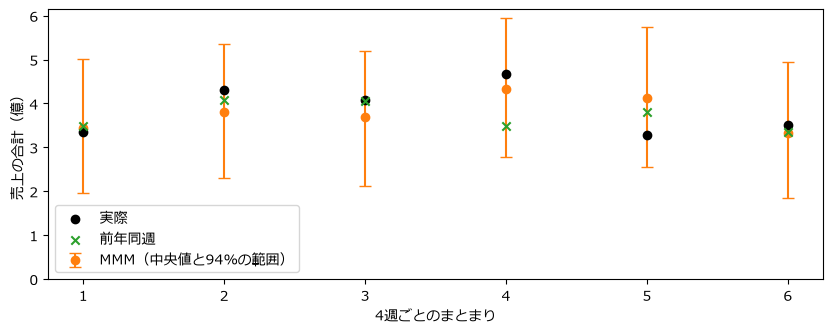

In [12]:
BLOCK = 4     # 何週間ごとにまとめるか

n_blocks = len(y_test) // BLOCK
use = n_blocks * BLOCK
actual_b = y_test[:use].reshape(n_blocks, BLOCK).sum(axis=1)
samples_b = samples_test[:, :use].reshape(-1, n_blocks, BLOCK).sum(axis=2)       # サンプル × ブロック
low_b, med_b, high_b = np.quantile(samples_b, [0.03, 0.5, 0.97], axis=0)
last_year_b = naive_last_year[:use].reshape(n_blocks, BLOCK).sum(axis=1)

print(f"{BLOCK}週ごとの合計（{n_blocks}個）")
print(f"MMM の平均誤差率: {np.mean(np.abs(actual_b - med_b) / actual_b):.1%}")
print(f"前年同週の平均誤差率: {np.mean(np.abs(actual_b - last_year_b) / actual_b):.1%}")
print(f"94%の範囲に入った割合: {((actual_b >= low_b) & (actual_b <= high_b)).mean():.0%}")

x = np.arange(1, n_blocks + 1)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.errorbar(x, med_b / 1e8, yerr=[(med_b - low_b) / 1e8, (high_b - med_b) / 1e8], fmt="o", color="C1", capsize=4, label="MMM（中央値と94%の範囲）")
ax.scatter(x, actual_b / 1e8, color="black", zorder=3, label="実際")
ax.scatter(x, last_year_b / 1e8, color="C2", marker="x", zorder=3, label="前年同週")
ax.set_xticks(x)
ax.set_xlabel(f"{BLOCK}週ごとのまとまり")
ax.set_ylabel("売上の合計（億）")
ax.set_ylim(0, None)
ax.legend();

**読み方**（`BLOCK` を変えた結果）

| まとめる単位 | MMM の平均誤差率 | 前年同週の平均誤差率 |
|---|---|---|
| 1週 | 26.2% | 24.0% |
| 2週 | 16.2% | 18.7% |
| 4週 | 10.4% | 9.3% |
| 13週 | 6.4% | 2.9% |
| 26週 | 1.3% | 3.1% |

- まとめる期間が長いほど、誤差率は小さくなります。週ごとの上下は互いに打ち消し合うからです
- 26週の合計では、予測24.4億（94%の範囲 20.2〜28.7億）に対して実際は24.7億。**半年の合計なら、1〜2%の誤差で当たっています**
- どの単位でも、MMM と前年同週は勝ったり負けたりで、はっきりした差はありません

MMM が答えるのに向いているのは、「来週の売上」ではなく「四半期や半期の合計」のような、まとまった期間の問いです。

## 7. この結果は何を意味するか

分かったことを整理します。

**良い知らせ**

1. **過学習はしていない**。学習期間とテスト期間で、誤差率がほぼ同じでした
2. **全体の水準は当たる**。広告の出し方が大きく変わった期間（新聞がほぼ停止、広告費は3分の2）でも、半年の合計は1〜2%の誤差でした
3. **予測の幅はうそをついていない**。実際の売上はすべて94%の範囲に入りました（むしろ少し広すぎます）

**悪い知らせ**

4. **週ごとの上下は当てられない**。年末を除くと、モデルが説明できる変動はごくわずかです
5. **「前年同週」という単純な予測と同じ程度**。広告費の情報を使っても、予測はほとんど良くなっていません

**MMMの価値はどこにあるのか**

「前年同週」は予測はできますが、「広告を20%減らしたらどうなるか」「どのチャネルが効いているか」には答えられません。
MMMの役割は、売上を当てることではなく、**売上を要因に分けて、広告を変えたときの違いを比べること**です。

**ただし、ここに大事な注意があります。**

- 予測が当たることは、要因への分け方が正しいことの**必要条件**ですが、**十分条件ではありません**
- たとえば「ベース80%・広告20%」のモデルと「ベース50%・広告50%」のモデルは、売上の予測がほぼ同じになることがあります。第5回で、広告の貢献が22%〜57%と幅広かったのは、まさにこのためです
- 今回は「広告の情報を使っても予測が良くならなかった」ので、この検証は第5回の ROAS が正しいことの強い裏づけにはなっていません

ROAS のような「原因と結果」の数字を確かめるには、予測精度の検証だけでは足りず、**実験**（出稿を止める・増やすテスト）が必要です。第5回の小課題で出てきた提案と同じ結論です。

> 本家は、1回の分割だけでなく、分割の位置をずらしながら何度も検証する方法（時系列の交差検証）を次の一歩として勧めています。
> 今回の評価は26週・1回だけなので、偶然の影響を受けている可能性があります。

## 8. 小課題

自分の答えを考えてから「答えを見る」を開いてください。

**課題1**　テスト期間の平均誤差率は26%でした。「精度74%のモデルです」と説明してよいでしょうか。

<details>
<summary>答えを見る</summary>

勧めません。理由は2つです。

1. **比べる相手がないと意味が分からない**。「去年の同じ週を見る」だけで誤差率24%でした。26%は、単純な方法と同じ程度です
2. **「精度74%」は誤解を招く**。週ごとの売上を74%の確率で当てる、という意味に取られかねません

伝えるなら「半年の合計では誤差1〜2%、週ごとでは誤差が約26%あり、これは前年同週を見る方法と同じ程度です」と、単位と比較相手を添えます。

</details>

**課題2**　学習期間の R² は0.69でしたが、年末を除くと0.16でした。なぜこんなに変わるのでしょうか。

<details>
<summary>答えを見る</summary>

R² は「売上のばらつきのうち、モデルが説明できた割合」です。
学習期間全体では、ばらつきの大部分が「年末の大きな山」から来ています。モデルは季節と祝日でこの山を説明できるので、R² が高くなります。

年末を除くと、残るのはふだんの週の小さな上下だけです。これは季節でも祝日でも広告でもあまり説明できておらず、R² は低くなります。

教訓：強い季節性のあるデータでは、R² は高く出やすい。「季節を当てているだけ」ではないかを、時期を分けて確かめます。

</details>

**課題3**　上司から「来月の週ごとの売上を予測してほしい。MMMでできますか」と頼まれました。どう答えますか。

<details>
<summary>答えを見る</summary>

「できますが、週ごとの予測なら、もっと簡単な方法（前年同週や、時系列の予測手法）と精度は変わりません」と正直に伝えます。

そのうえで、MMMが役に立つ場面を提案します。

- 「広告費を増やした場合・減らした場合」の比較（単純な方法ではできない）
- 四半期や半期の合計の見通し（幅つきで）
- どのチャネルの予算を動かすかの判断材料

頼まれたことをそのまま引き受けるのではなく、「その目的なら、こちらの方法が合っています」と言えることが、信頼につながります。

</details>

**課題4**　テスト期間には、新聞広告がほぼ止まっていました。これは検証にとって、どんな意味がありますか。

<details>
<summary>答えを見る</summary>

**良い面**：広告の出し方が変わっても全体の水準を当てられたので、「学習期間のパターンを丸暗記しただけ」ではないことが分かります。

**限界**：新聞の効果そのものを確かめられたわけではありません。同じ時期に DM や TV も減り、ソーシャルは増えています。複数が同時に動いているので、どれの影響かは分けられません。予測の幅も広いので、新聞の効果が推定の半分でも2倍でも、予測は「範囲内」に収まってしまいます。

1つのチャネルだけを、決めた地域や期間で止める。これが実験で、効果を分けて測るにはこの形が必要です。

</details>

## 9. まとめ

- 学習用データへの当てはまりだけでは、過学習を見抜けない。**モデルが見ていないデータ**で検証する
- テスト期間（26週）は、年末を含まず、広告の出し方も学習期間と違っていた
- **結果**
  - 平均誤差率は学習期間25%、テスト期間26%。過学習はしていない
  - 半年の合計は1〜2%の誤差で当たる。週ごとの上下は当たらない（R² はほぼ0）
  - 学習期間の R² 0.69 は、年末の山のおかげ。年末を除くと0.16
  - 「前年同週」という単純な予測と、同じ程度の精度
  - CRPS は学習期間0.181億、テスト期間0.161億で、本家と一致
- **指標は単独では意味を持たない**。単純な予測と比べる、期間を分けて見る、まとめる単位を変えて見る
- MMMの価値は売上の予測ではなく、**要因への分解と、広告を変えたときの比較**
- 予測が当たることは、分解が正しいことの必要条件だが十分条件ではない。ROAS を確かめるには実験が必要

**次回（第7回）**：予算最適化。限界ROASの考え方を使って、同じ総額で売上を増やす配分を探します。